# Combined figure: QD correlation matrix + index phases

Two existing figures side by side:

- **(a)** 7-13yr band correlation matrix (indices vs. ice/CAO/ocean
  variables), full column height.
- **(b), (c)** Greenland Sea ice anomaly and climate index phase ribbons,
  stacked on the right exactly as in `figure_index_phases.ipynb`.

Panels (b) and (c) are drawn with the same code, at the same size, as the
standalone `index_phases_full_winter.png`. Only panel (a) stretches, to
match their combined height, with its aspect ratio preserved.

Author: Chris Barrell


In [21]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from scipy import stats as scipy_stats
from pathlib import Path
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

import sys
sys.path.append('..')
from utils.logger import (setup_logger, log_data_loading, log_processing_step,
                          log_output_file, log_completion, log_error)

logger = setup_logger('correlation_and_phases_combined', config_path='../config.yaml')
start_time = datetime.now()


INFO     | ======================================================================
INFO     | Starting analysis: correlation_and_phases_combined
INFO     | Log file: outputs/logs/correlation_and_phases_combined_20261001_105715.log
INFO     | Timestamp: 2026-10-01 10:57:15
INFO     | ======================================================================


## Configuration


In [22]:
# ==== Panel (a): correlation matrix — from build_correlation_summary_matrix.py ====

# Must match whichever INDEX_SEASON you ran compute_trimmed_correlation_matrix.ipynb
# with -- 'DJFM' reads its default (unsuffixed) output directory, 'ONDJFMA' reads
# its '_indexONDJFMA'-suffixed one. This is now EXPLICIT rather than left to
# directory-search order: earlier versions of this notebook picked whichever
# trimmed_correlation_matrix* folder happened to exist first in the candidate
# list, which silently kept reading the old DJFM output even after re-running
# the source notebook with INDEX_SEASON='ONDJFMA' -- both directories exist
# side by side by design (that's the whole point of the suffix), so directory
# presence alone was never enough to tell them apart.
INDEX_SEASON = 'ONDJFMA'   # 'DJFM' | 'ONDJFMA' -- set this to match your last run
if INDEX_SEASON not in ('DJFM', 'ONDJFMA'):
    raise ValueError(f"INDEX_SEASON must be 'DJFM' or 'ONDJFMA', got {INDEX_SEASON!r}")
CORR_DIR_SUFFIX = '_indexONDJFMA' if INDEX_SEASON == 'ONDJFMA' else ''

CORR_DIR = Path(f'../../trimmed_correlation_matrix{CORR_DIR_SUFFIX}/')
CORR_DIR_CANDIDATES = [
    Path(f'../../trimmed_correlation_matrix{CORR_DIR_SUFFIX}'),
    Path(f'../trimmed_correlation_matrix{CORR_DIR_SUFFIX}'),
    Path(f'./trimmed_correlation_matrix{CORR_DIR_SUFFIX}'),
    Path(f'./outputs/processed_data/trimmed_correlation_matrix{CORR_DIR_SUFFIX}'),
    Path(f'./outputs/processed_data/climate_indices/trimmed_correlation_matrix{CORR_DIR_SUFFIX}'),
]
CORR_DIR_SEARCH_ROOTS = [Path('./outputs'), Path('..'), Path('../..')]

BAND = 'QD_7-13yr'   # single band for panel (a) — this figure, not the comparison

# NINO34 is NOT yet in the trimmed correlation matrix (same situation
# SCAND was in before compute_trimmed_correlation_matrix.ipynb was
# re-run with it added) -- it has been added to that notebook the same
# way, but panel (a) will only show real values once it's re-run. Until
# then the existing "requested but not found" warning below handles it
# gracefully rather than failing.
INDEX_WANTED = ['GBI_UL', 'NAO', 'AO', 'PDO', 'TPQD', 'SCAND', 'AD', 'NINO34']
INDEX_LABEL_MAP = {'GBI_UL': 'GBI', 'NAO': 'NAO', 'AO': 'AO', 'PDO': 'PDO',
                   'TPQD': 'TPQD', 'SCAND': 'SCAND', 'AD': 'AD', 'NINO34': 'NINO3.4'}

# Shared row order for both panels (a) and (c) -- CAO is appended after
# this, in panel (c) only, since panel (a) has no CAO row.
INDEX_DISPLAY_ORDER = ['GBI', 'NAO', 'SCAND', 'AO', 'AD', 'NINO3.4', 'TPQD', 'PDO']

TARGETS = ['greenland', 'CAO_index_early', 'CAO_index_late',
          'PSW_flux', 'AW_flux', 'UpperOcean_temp', 'UpperOcean_sal']
TARGET_LABELS = ['GS ice\nmax', 'CAO\nearly', 'CAO\nlate',
                 'PSW\nflux', 'AW\nflux', 'Upper\nocean\nT', 'Upper\nocean\nS']
GROUP_DIVIDERS = [3]

P_THRESHOLD = 0.05

# Significance scheme for the marker outlines in panel (a) (both versions).
# Selects WHICH p-value file is read from compute_trimmed_correlation_matrix
# (v1.4.0+) -- r values are identical in all three, only the outlines change.
#   'plain'     -- correlation_pvalues.csv (plain Pearson, original behaviour)
#   'neff'      -- correlation_pvalues_neff.csv (effective-sample-size t-test)
#   'surrogate' -- correlation_pvalues_surrogate.csv (Ebisuzaki phase-randomised)
P_METHOD = 'surrogate'   # 'plain' | 'neff' | 'surrogate'
P_FILES = {'plain': 'correlation_pvalues.csv',
           'neff': 'correlation_pvalues_neff.csv',
           'surrogate': 'correlation_pvalues_surrogate.csv'}
if P_METHOD not in P_FILES:
    raise ValueError(f"P_METHOD must be one of {list(P_FILES)}, got {P_METHOD!r}")
P_FILE = P_FILES[P_METHOD]

# The alternative figure's UNFILTERED triplet comes from a different source
# (compute_monthly_ondjfma_correlations.ipynb), so P_METHOD does not reach
# it -- choose its p-value column explicitly here. 'p_plain' is the
# original behaviour; set to that CSV's effective-N column name to use it
# (the column names available are listed in the error if this is wrong).
UNFILTERED_P_COL = 'p_plain'

# Output suffix -- empty for the original plain/plain combination, so the
# existing figure filenames are unchanged and never overwritten by a
# corrected run.
P_SUFFIX = '' if P_METHOD == 'plain' else f'_p{P_METHOD}'
P_SUFFIX_ALT = P_SUFFIX + ('' if UNFILTERED_P_COL == 'p_plain' else f'_unfilt-{UNFILTERED_P_COL}')
CMAP_MATRIX = 'RdBu_r'
VLIM_MATRIX = 1.0
MIN_MARKER_SIZE = 110
MARKER_SCALE = 780
FONT_SIZE_VALUE = 6.5

# Panel (a)'s ORIGINAL single-panel size, used only to derive its aspect
# ratio (width / height) — this figure stretches (a) to the combined
# height of (b)+(c) while preserving that ratio, not this exact size.
MATRIX_PANEL_WIDTH_ORIG  = 5.2
MATRIX_PANEL_HEIGHT_ORIG = 4.4
MATRIX_ASPECT = MATRIX_PANEL_WIDTH_ORIG / MATRIX_PANEL_HEIGHT_ORIG

# ==== Panels (b), (c): index phases — from build_index_phases.py =========
CLIMATE_NC = Path('./outputs/processed_data/climate_indices/all_climate_indices.nc')
INDEX_RAW_DIR = Path('/local/jbj13rpu/Documents/ROVER/climate_indices/raw')

# AO, TPQD and SCAND deliberately dropped here (panel (c)/ribbons only --
# panel (a)'s correlation matrix still includes them via INDEX_WANTED
# above, which reads from the trimmed-correlation-matrix CSVs, not this
# list). AD added -- already in all_climate_indices.nc (written by
# compute_arctic_dipole.ipynb), no raw-file fallback needed.
INDEX_SPEC = [
    dict(label='GBI',   nc_aliases=['GBI_UL', 'GBI', 'gbi'],
         raw_file='gbi_mon.csv', reader='psl_csv'),
    dict(label='NAO',   nc_aliases=['NAO', 'nao'],
         raw_file='NAO.data', reader='psl_data'),
    dict(label='PDO',   nc_aliases=['PDO', 'pdo'],
         raw_file='PDO.data', reader='psl_data'),
    dict(label='NINO3.4', nc_aliases=['NINO34', 'nino34'],
         raw_file='NINO34.data', reader='psl_data'),
    dict(label='AD',    nc_aliases=['AD', 'ad'],
         raw_file=None, reader=None),
]
MISSING_SENTINELS = [-999.0, -99.9, -99.99, -9999.0, -99.0]

ICE_NC_MONTHLY   = Path('/local/jbj13rpu/Documents/ROVER/gs_ice_study/notebooks/'
                        'outputs/processed_data/osisaf_sii_v3/osisaf_sii_v3_all_regions.nc')
ICE_VAR          = 'ice_extent_greenland_monthly'
OSISAF_DAILY_DIR = Path('../../osi-sea_ice_index/')
OSISAF_GS_REGION = 'fram'
OSISAF_MIN_DAYS  = 30

CAO_PROCESSED_DIR = Path('./outputs/processed_data/figure_06')
SHOW_CAO_ROWS = True

EARLY_WINTER_MONTHS = [10, 11, 12, 1]
LATE_WINTER_MONTHS  = [2, 3, 4]
FULL_WINTER_MONTHS  = EARLY_WINTER_MONTHS + LATE_WINTER_MONTHS
SEASONS_FULL = [('full', 'ONDJFMA', FULL_WINTER_MONTHS)]
REQUIRE_COMPLETE_SEASON = True

ANALYSIS_START = 1979
ANALYSIS_END   = 2025
SPLIT_YEAR     = 2015

CMAP_PHASE    = 'RdBu_r'
PHASE_VLIM    = 2.0
COLOR_ICE_POS = '#3B6E8F'
COLOR_ICE_NEG = '#B03A2E'

# Panels (b)+(c)'s ORIGINAL size — unchanged, this is the fixed anchor the
# rest of the figure is built around.
RIBBON_WIDTH = 10.0
RIBBON_HEIGHT = None   # computed below once n_ribbon is known: 3.0 + 0.34*n

# ==== Output ===============================================================
OUTPUT_DIR         = Path('./outputs/figures/')
PROCESSED_DIR      = Path('./outputs/processed_data/correlation_and_phases_combined')
OUTPUT_METHODS_DIR = Path('./outputs/methods')
for d in (OUTPUT_DIR, PROCESSED_DIR, OUTPUT_METHODS_DIR):
    d.mkdir(parents=True, exist_ok=True)

DPI = 600


## Panel (a) data: locate and load the QD correlation matrix

Same auto-discovery as `figure_correlation_summary_matrix.ipynb` — tries
`CORR_DIR`, then the candidates, then a recursive search, rather than
failing on one hard-coded path.


In [23]:
def discover_bands(root):
    if not root.is_dir():
        return []
    return sorted(d.name for d in root.iterdir()
                 if d.is_dir() and (d / 'correlation_matrix.csv').exists()
                 and (d / 'correlation_pvalues.csv').exists())


def locate_corr_dir():
    for cand in [CORR_DIR] + CORR_DIR_CANDIDATES:
        bands = discover_bands(cand)
        if bands:
            logger.info(f'  Using {cand.resolve()}')
            return cand, bands
    logger.warning('  No candidate path worked — searching recursively')
    for root in CORR_DIR_SEARCH_ROOTS:
        if not root.is_dir():
            continue
        for hit in root.rglob('correlation_matrix.csv'):
            parent = hit.parent.parent
            bands = discover_bands(parent)
            if bands:
                logger.info(f'  Found via search: {parent.resolve()}')
                return parent, bands
    raise FileNotFoundError(
        'Could not locate correlation-matrix band folders. '
        f'Tried: {[str(p) for p in [CORR_DIR] + CORR_DIR_CANDIDATES]} '
        f'and searched under {[str(p) for p in CORR_DIR_SEARCH_ROOTS]}. '
        'Set CORR_DIR above to the correct path.'
    )


log_processing_step(logger, 'Locating correlation matrices')
found_corr_dir, available_bands = locate_corr_dir()
if BAND not in available_bands:
    raise FileNotFoundError(
        f"Band '{BAND}' not found. Available: {available_bands}"
    )

# Loud, hard-to-miss confirmation of exactly what's about to be plotted --
# this is precisely the check that would have caught reading the wrong
# (stale DJFM) directory after re-running the source notebook with
# INDEX_SEASON='ONDJFMA': the two output directories coexist by design, so
# a quiet log line alone was not enough to notice using the wrong one.
resolved_name = found_corr_dir.resolve().name
expected_suffix_present = bool(CORR_DIR_SUFFIX) and CORR_DIR_SUFFIX in resolved_name
expected_suffix_absent = (not CORR_DIR_SUFFIX) and 'indexONDJFMA' not in resolved_name
if not (expected_suffix_present or expected_suffix_absent):
    raise RuntimeError(
        f"INDEX_SEASON={INDEX_SEASON!r} expects a directory "
        f"{'containing' if CORR_DIR_SUFFIX else 'NOT containing'} "
        f"'{CORR_DIR_SUFFIX or 'indexONDJFMA'}', but resolved to "
        f"'{resolved_name}' instead. This means CORR_DIR_CANDIDATES found "
        f"an unexpected directory -- check that both variants of "
        f"compute_trimmed_correlation_matrix.ipynb's output actually exist "
        f"where expected before trusting anything downstream."
    )
print(f">>> Panel (a) correlation matrix: INDEX_SEASON={INDEX_SEASON!r}, "
     f"reading from {found_corr_dir.resolve()}")
logger.info(f"Confirmed: INDEX_SEASON={INDEX_SEASON!r} <-> {resolved_name}")

r_df = pd.read_csv(found_corr_dir / BAND / 'correlation_matrix.csv', index_col=0)
_p_path = found_corr_dir / BAND / P_FILE
if not _p_path.exists():
    raise FileNotFoundError(
        f"P_METHOD={P_METHOD!r} needs {_p_path}, which does not exist -- re-run "
        f"compute_trimmed_correlation_matrix.ipynb (v1.4.0+, COMPUTE_CORRECTED_P=True) "
        f"with INDEX_SEASON={INDEX_SEASON!r}, or set P_METHOD='plain'."
    )
p_df = pd.read_csv(_p_path, index_col=0)
print(f">>> Panel (a) significance: P_METHOD={P_METHOD!r} ({P_FILE})")

_present = [i for i in INDEX_WANTED if i in r_df.index]
_absent = [i for i in INDEX_WANTED if i not in r_df.index]
if _absent:
    logger.warning(f'  Requested indices not in the matrix: {_absent} '
                   f'(available: {sorted(r_df.index)})')

# Apply INDEX_DISPLAY_ORDER; anything present but not in that list is
# appended at the end rather than dropped.
_present_labels = {INDEX_LABEL_MAP.get(i, i): i for i in _present}
INDEX_LABELS_MATRIX = ([lab for lab in INDEX_DISPLAY_ORDER if lab in _present_labels]
                       + [lab for lab in _present_labels
                          if lab not in INDEX_DISPLAY_ORDER])
INDICES = [_present_labels[lab] for lab in INDEX_LABELS_MATRIX]

missing_tgt = [t for t in TARGETS if t not in r_df.columns]
if missing_tgt:
    raise KeyError(f'Missing columns {missing_tgt}. Available: {sorted(r_df.columns)}')

logger.info(f'  Panel (a): {BAND}, indices {INDEX_LABELS_MATRIX}')


INFO     | Processing: Locating correlation matrices
INFO     |   Using /local/jbj13rpu/Documents/ROVER/gs_ice_study/notebooks/outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA
>>> Panel (a) correlation matrix: INDEX_SEASON='ONDJFMA', reading from /local/jbj13rpu/Documents/ROVER/gs_ice_study/notebooks/outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA
INFO     | Confirmed: INDEX_SEASON='ONDJFMA' <-> trimmed_correlation_matrix_indexONDJFMA
>>> Panel (a) significance: P_METHOD='surrogate' (correlation_pvalues_surrogate.csv)
INFO     |   Panel (a): QD_7-13yr, indices ['GBI', 'NAO', 'SCAND', 'AO', 'AD', 'NINO3.4', 'TPQD', 'PDO']


## Panels (b), (c) data: indices, ice, CAO


In [24]:
def _mask_missing(s):
    for mv in MISSING_SENTINELS:
        s = s.mask(np.isclose(s, mv))
    return s


def read_psl_data(path):
    lines = Path(path).read_text().splitlines()
    recs = []
    for ln in lines[1:]:
        parts = ln.split()
        if len(parts) != 13:
            continue
        try:
            yr = int(parts[0])
            vals = [float(v) for v in parts[1:]]
        except ValueError:
            continue
        if not (1800 < yr < 2100):
            continue
        for m, v in enumerate(vals, start=1):
            recs.append((pd.Timestamp(yr, m, 1), v))
    if not recs:
        raise ValueError(f'No parseable rows in {path}')
    return _mask_missing(pd.Series(dict(recs)).sort_index())


def read_psl_csv(path):
    df = pd.read_csv(path, skiprows=1, header=None, names=['date', 'value'])
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df = df.dropna(subset=['date'])
    s = pd.Series(df['value'].astype(float).values, index=df['date']).sort_index()
    return _mask_missing(s)


READERS = {'psl_data': read_psl_data, 'psl_csv': read_psl_csv}


def load_climate_nc():
    if not CLIMATE_NC.exists():
        logger.warning(f'  {CLIMATE_NC} not found — using raw files only')
        return {}
    ds = xr.open_dataset(CLIMATE_NC)
    out = {}
    for name in ds.data_vars:
        da = ds[name]
        if 'time' not in da.dims or da.ndim != 1:
            continue
        out[name.lower()] = _mask_missing(da.to_series().sort_index())
    return out


def resolve_index(spec, nc_vars):
    for alias in spec['nc_aliases']:
        if alias.lower() in nc_vars:
            return nc_vars[alias.lower()], f"{CLIMATE_NC.name}:{alias}"
    if spec['raw_file'] is None:
        raise KeyError(
            f"{spec['label']}: not in {CLIMATE_NC.name} "
            f"(tried {spec['nc_aliases']}; available: {sorted(nc_vars)}) "
            f"and no raw-file fallback defined."
        )
    path = INDEX_RAW_DIR / spec['raw_file']
    if not path.exists():
        raise FileNotFoundError(f"{spec['label']}: {path} not found")
    return READERS[spec['reader']](path), f"raw:{path.name}"


def seasonal_mean_from_monthly(s, months, complete=REQUIRE_COMPLETE_SEASON):
    idx = pd.DatetimeIndex(s.index)
    keep = idx.month.isin(months)
    sub = s[keep]
    season_yr = np.where(idx.month[keep] >= 10, idx.year[keep] + 1, idx.year[keep])
    df = pd.DataFrame({'value': np.asarray(sub.values), 'year': season_yr})
    grouped = df.groupby('year')['value']
    means = grouped.mean()
    if complete:
        means = means.where(grouped.count() == len(months))
    return means


def _seasonal_max(times, values, min_days):
    times = pd.DatetimeIndex(times)
    winter_years = np.where(times.month >= 10, times.year + 1, times.year)
    in_window = np.isin(times.month, FULL_WINTER_MONTHS)
    winter_years = winter_years[in_window]
    values_win = np.asarray(values)[in_window]
    years_out, extremes = [], []
    for yr in np.unique(winter_years):
        mask = winter_years == yr
        if mask.sum() < min_days:
            continue
        vals = values_win[mask]
        if np.all(np.isnan(vals)):
            continue
        years_out.append(yr)
        extremes.append(np.nanmax(vals))
    return np.array(years_out), np.array(extremes)


def load_ice_max():
    if ICE_NC_MONTHLY.exists():
        ds = xr.open_dataset(ICE_NC_MONTHLY)
        if ICE_VAR in ds.data_vars:
            da = ds[ICE_VAR].load()
            if da.ndim == 1:
                logger.info(f'  Ice from monthly cache: {ICE_VAR}')
                return _seasonal_max(da.time.values, da.values, min_days=1)
        logger.warning(f"  '{ICE_VAR}' unusable in monthly cache, using daily source")
    if not OSISAF_DAILY_DIR.exists():
        raise FileNotFoundError(f'Neither monthly cache nor {OSISAF_DAILY_DIR} usable.')
    sie_list = []
    for fname in os.listdir(OSISAF_DAILY_DIR):
        d = xr.open_dataset(OSISAF_DAILY_DIR / fname)
        sie_list.append(d.sie.rename(fname.split('_')[1]))
    gs = next((s for s in sie_list if s.name == OSISAF_GS_REGION), None)
    if gs is None:
        raise ValueError(f"Region '{OSISAF_GS_REGION}' not found")
    return _seasonal_max(gs.time.values, gs.values, OSISAF_MIN_DAYS)


log_processing_step(logger, 'Loading climate indices and ice')

nc_vars = load_climate_nc()
index_series = {}
for spec in INDEX_SPEC:
    monthly, source = resolve_index(spec, nc_vars)
    valid = monthly.dropna()
    logger.info(f"  {spec['label']:6s} <- {source:40s} {len(valid)} valid months")
    for season_key, season_label, months in SEASONS_FULL:
        index_series[(spec['label'], season_key)] = \
            seasonal_mean_from_monthly(monthly, months)
_loaded_phase = [s['label'] for s in INDEX_SPEC]
INDEX_LABELS_PHASE = ([lab for lab in INDEX_DISPLAY_ORDER if lab in _loaded_phase]
                      + [lab for lab in _loaded_phase if lab not in INDEX_DISPLAY_ORDER])

ice_years, ice_values = load_ice_max()
ice = pd.Series(ice_values, index=ice_years.astype(int))
ice = ice[(ice.index >= ANALYSIS_START) & (ice.index <= ANALYSIS_END)]
logger.info(f'  Ice: {len(ice)} winters, {ice.index.min()}-{ice.index.max()}')

cao_series = {}
if SHOW_CAO_ROWS:
    for season_key, fname in [('early', 'cao_index_early.csv'),
                              ('late',  'cao_index_late.csv')]:
        path = CAO_PROCESSED_DIR / fname
        if not path.exists():
            logger.warning(f'  CAO CSV not found at {path} — skipping CAO row')
            cao_series = {}
            break
        df = pd.read_csv(path)
        cao_series[season_key] = pd.Series(df['cao_index'].values,
                                          index=df['year'].astype(int))
    if cao_series:
        n_e, n_l = len(EARLY_WINTER_MONTHS), len(LATE_WINTER_MONTHS)
        e, l = cao_series['early'], cao_series['late']
        common = e.index.intersection(l.index)
        cao_series['full'] = ((n_e * e.reindex(common) + n_l * l.reindex(common))
                              / (n_e + n_l))


INFO     | Processing: Loading climate indices and ice
INFO     |   GBI    <- all_climate_indices.nc:GBI_UL            2096 valid months
INFO     |   NAO    <- all_climate_indices.nc:NAO               919 valid months
INFO     |   PDO    <- all_climate_indices.nc:PDO               932 valid months
INFO     |   NINO3.4 <- all_climate_indices.nc:NINO34            943 valid months
INFO     |   AD     <- all_climate_indices.nc:AD                920 valid months
INFO     |   Ice from monthly cache: ice_extent_greenland_monthly
INFO     |   Ice: 47 winters, 1979-2025


In [25]:
years = np.arange(ANALYSIS_START, ANALYSIS_END + 1)


def zscore_on_period(s):
    s = s.reindex(years)
    ref = s.dropna()
    if len(ref) < 3:
        return s * np.nan
    return (s - ref.mean()) / ref.std()


z_index = {k: zscore_on_period(v) for k, v in index_series.items()}
z_cao   = {k: zscore_on_period(v) for k, v in cao_series.items()}
z_ice   = zscore_on_period(ice)

RIBBON_ROWS = [(lab, 'full', 'ONDJFMA') for lab in INDEX_LABELS_PHASE]
if z_cao:
    RIBBON_ROWS = [('CAO', 'full', 'ONDJFMA')] + RIBBON_ROWS
N_RIBBON = len(RIBBON_ROWS)
RIBBON_HEIGHT = 3.0 + 0.34 * N_RIBBON   # matches build_index_phases.py exactly
logger.info(f'  {N_RIBBON} ribbon rows -> panels (b)+(c) height {RIBBON_HEIGHT:.2f}in')


INFO     |   6 ribbon rows -> panels (b)+(c) height 5.04in


## Combined figure

Outer layout: 1 row, 2 columns. Left column is panel (a), sized to the
combined height of (b)+(c) with its original aspect ratio preserved. Right
column is a nested 2-row grid with the exact height ratio
`build_index_phases.py` uses, so (b) and (c) are pixel-for-pixel the same
shapes as the standalone figure — only their position on the page changes.


INFO     | Processing: Creating combined figure
INFO     | Created figure: correlation_and_phases_combined_psurrogate.png


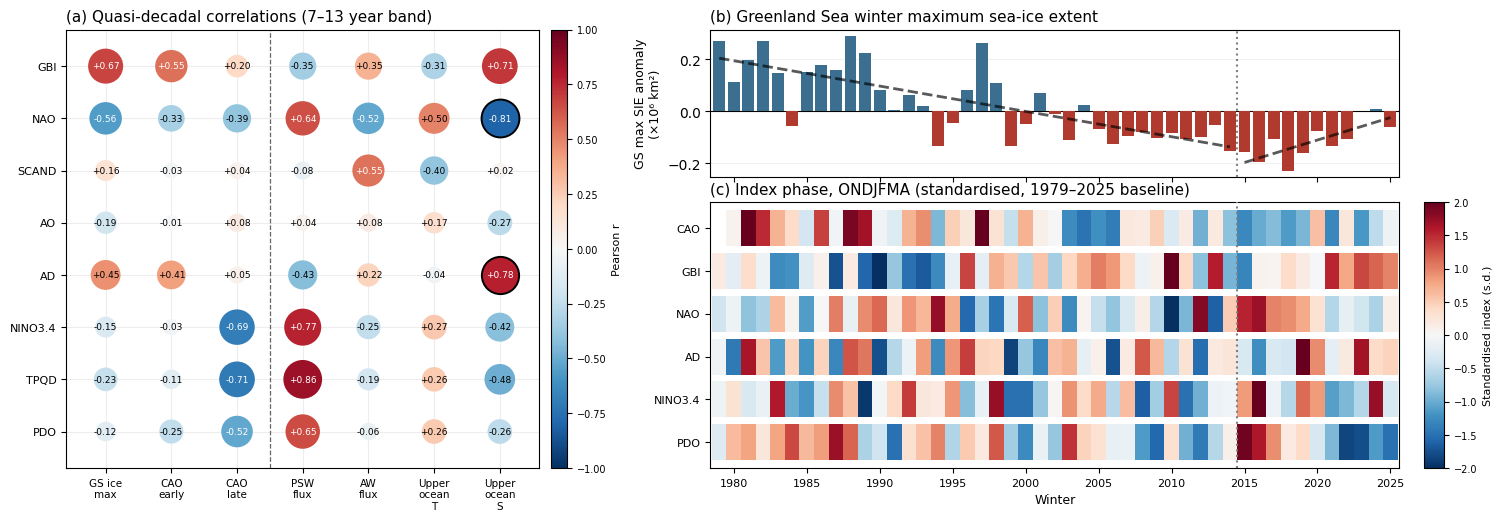

In [26]:
log_processing_step(logger, 'Creating combined figure')

total_height = RIBBON_HEIGHT
matrix_data_width = total_height * MATRIX_ASPECT
# Panel (a)'s colorbar gets its own reserved sub-column width, rather than
# a floating axis positioned by offsetting from ax_a's bounding box. That
# earlier approach broke once wspace was tightened: the offset collided
# with panel (c)'s row labels, which don't show up in any axes' plain
# get_position() (only a tight-bbox measurement sees them). Reserving the
# space in the gridspec itself is robust to wspace/width changes.
# Shared by BOTH colorbars, so they render at the same width (panel c's
# is defined in figure-fraction via add_axes, so its width is derived
# from this inches value once total_width is known, further down).
CBAR_WIDTH_IN = 0.20
CBAR_A_PAD_BEFORE = 0.15   # gap between panel (a)'s plot and its colorbar
CBAR_A_PAD_AFTER  = 0.15   # space for the colorbar's own tick labels
matrix_col_width = (matrix_data_width + CBAR_A_PAD_BEFORE
                    + CBAR_WIDTH_IN + CBAR_A_PAD_AFTER)
total_width = matrix_col_width + RIBBON_WIDTH

fig = plt.figure(figsize=(total_width, total_height))
outer = fig.add_gridspec(1, 2, width_ratios=[matrix_col_width, RIBBON_WIDTH],
                         wspace=0.04, left=0.12, right=0.93, top=0.95, bottom=0.08)
left_gs = outer[0].subgridspec(
    1, 4, width_ratios=[matrix_data_width, CBAR_A_PAD_BEFORE,
                        CBAR_WIDTH_IN, CBAR_A_PAD_AFTER], wspace=0)

# ==================================================================
# PANEL (a): correlation matrix — drawing logic matches
# build_correlation_summary_matrix.py's make_matrix_figure exactly,
# adapted from its own standalone figure/axes into this subplot.
# ==================================================================
ax_a = fig.add_subplot(left_gs[0, 0])
norm_a = TwoSlopeNorm(vmin=-VLIM_MATRIX, vcenter=0, vmax=VLIM_MATRIX)
cmap_a = plt.get_cmap(CMAP_MATRIX)

for j, tgt in enumerate(TARGETS):
    for i, idx in enumerate(INDICES):
        rv, pv = r_df.loc[idx, tgt], p_df.loc[idx, tgt]
        y = len(INDICES) - 1 - i
        ax_a.scatter(j, y, s=MIN_MARKER_SIZE + MARKER_SCALE * abs(rv),
                    c=[cmap_a(norm_a(rv))],
                    edgecolors='k' if pv < P_THRESHOLD else 'none',
                    linewidths=1.4, zorder=3)
        # Significance is shown by the marker's black outline alone
        # (edgecolors, set above) -- no asterisk needed alongside it.
        ax_a.text(j, y, f'{rv:+.2f}', ha='center', va='center',
                 fontsize=FONT_SIZE_VALUE, zorder=4,
                 color='w' if abs(rv) > 0.5 else 'k')

for g in GROUP_DIVIDERS:
    ax_a.axvline(g - 0.5, color='0.4', linewidth=0.9, linestyle='--', zorder=1)

ax_a.set_xticks(range(len(TARGETS)))
ax_a.set_xticklabels(TARGET_LABELS, fontsize=7.5)
ax_a.set_xlim(-0.6, len(TARGETS) - 0.4)
ax_a.set_ylim(-0.7, len(INDICES) - 0.3)
ax_a.set_yticks(range(len(INDICES)))
ax_a.set_yticklabels(INDEX_LABELS_MATRIX[::-1], fontsize=8)
ax_a.set_title('(a) Quasi-decadal correlations (7–13 year band)',
              fontsize=11, loc='left')
ax_a.grid(alpha=0.22, zorder=0)
ax_a.set_axisbelow(True)

cbar_a_ax = fig.add_subplot(left_gs[0, 2])
cb_a = fig.colorbar(plt.cm.ScalarMappable(norm=norm_a, cmap=cmap_a), cax=cbar_a_ax)
# Default right-side ticks/label. They spill rightward from cbar_a_ax into
# CBAR_A_GAP, the dedicated trailing sub-column, not the outer wspace gap
# shared with panel (b)/(c) -- that's what collided with panel (c)'s row
# labels in an earlier version with left-side ticks and gap-then-cbar order.
cb_a.set_label('Pearson r', fontsize=8)
cb_a.ax.tick_params(labelsize=7)

# ==================================================================
# PANELS (b), (c): ice anomaly + phase ribbons — drawing logic matches
# build_index_phases.py's make_phase_figure exactly (same height ratio,
# same colours, same axes formatting). Nested inside the right column
# rather than its own standalone figure.
# ==================================================================
# subgridspec doesn't accept left/right margin kwargs on this matplotlib
# version, so the margin for panel (c)'s row labels is reserved with an
# unused spacer column instead (13% of the ribbon column's width, matching
# the standalone figure's left=0.13 margin on its own 10in-wide figure).
right_split = outer[1].subgridspec(1, 2, width_ratios=[0.13, 0.85], wspace=0)
inner = right_split[0, 1].subgridspec(2, 1, height_ratios=[1.0, max(1.4, 0.30 * N_RIBBON)],
                                      hspace=0.12)

xlim = (ANALYSIS_START - 0.6, ANALYSIS_END + 0.6)

# ---- (b) ice anomaly ----------------------------------------------------
ax_b = fig.add_subplot(inner[0])
ice_full = ice.reindex(years)
ice_anom = ice_full - ice_full.dropna().mean()
bar_colors = [COLOR_ICE_POS if v >= 0 else COLOR_ICE_NEG
              for v in ice_anom.fillna(0)]
ax_b.bar(years, ice_anom.values, color=bar_colors, width=0.82, zorder=3)
ax_b.axhline(0, color='k', linewidth=0.8, zorder=2)
ax_b.axvline(SPLIT_YEAR - 0.5, color='gray', linestyle=':', linewidth=1.5, zorder=4)

for mask in (years < SPLIT_YEAR, years >= SPLIT_YEAR):
    yy, vv = years[mask], ice_anom.values[mask]
    ok = np.isfinite(vv)
    if ok.sum() > 2:
        sl_, ic_, *_ = scipy_stats.linregress(yy[ok], vv[ok])
        ax_b.plot(yy[ok], sl_ * yy[ok] + ic_, '--', color='k',
                 linewidth=2, alpha=0.65, zorder=5)

ax_b.set_ylabel('GS max SIE anomaly\n(\u00d710\u2076 km\u00b2)', fontsize=9)
ax_b.set_title('(b) Greenland Sea winter maximum sea-ice extent',
              fontsize=11, loc='left')
ax_b.grid(True, alpha=0.25, linewidth=0.5, axis='y')
ax_b.set_axisbelow(True)
ax_b.set_xlim(*xlim)
ax_b.tick_params(labelbottom=False)

# ---- (c) phase ribbons ---------------------------------------------------
ax_c = fig.add_subplot(inner[1], sharex=ax_b)
norm_c = TwoSlopeNorm(vmin=-PHASE_VLIM, vcenter=0, vmax=PHASE_VLIM)
cmap_c = plt.get_cmap(CMAP_PHASE)

ytick_pos, ytick_lab = [], []
for i, (lab, sk, sl) in enumerate(RIBBON_ROWS):
    y = N_RIBBON - 1 - i
    series = (z_cao[sk] if lab == 'CAO' else z_index[(lab, sk)]).reindex(years)
    for yr, v in series.items():
        if not np.isfinite(v):
            continue
        ax_c.add_patch(Rectangle(
            (yr - 0.5, y - 0.42), 1.0, 0.84,
            facecolor=cmap_c(norm_c(np.clip(v, -PHASE_VLIM, PHASE_VLIM))),
            edgecolor='none', zorder=3))
    ytick_pos.append(y)
    ytick_lab.append(lab)

ax_c.axvline(SPLIT_YEAR - 0.5, color='gray', linestyle=':', linewidth=1.5, zorder=5)
ax_c.set_yticks(ytick_pos)
ax_c.set_yticklabels(ytick_lab, fontsize=8)
ax_c.set_ylim(-0.6, N_RIBBON - 0.4)
ax_c.set_xlim(*xlim)
ax_c.xaxis.set_major_locator(ticker.MultipleLocator(5))
ax_c.tick_params(labelbottom=True, labelsize=8)
ax_c.set_xlabel('Winter', fontsize=9)
ax_c.set_title(f'(c) Index phase, ONDJFMA (standardised, '
              f'{ANALYSIS_START}\u2013{ANALYSIS_END} baseline)',
              fontsize=11, loc='left')

_pc = ax_c.get_position()
cbar_c_width_frac = CBAR_WIDTH_IN / total_width
cbar_c_ax = fig.add_axes([_pc.x1 + 0.015, _pc.y0, cbar_c_width_frac, _pc.height])
cb_c = fig.colorbar(plt.cm.ScalarMappable(norm=norm_c, cmap=cmap_c), cax=cbar_c_ax)
cb_c.set_label('Standardised index (s.d.)', fontsize=8)
cb_c.ax.tick_params(labelsize=7)

fname = f'correlation_and_phases_combined{P_SUFFIX}.png'
fig.savefig(OUTPUT_DIR / fname, dpi=DPI, bbox_inches='tight')
log_output_file(logger, 'figure', OUTPUT_DIR / fname)
plt.show()


In [27]:
P_METHOD_TXT = {
    'plain': ("Plain Pearson p -- does NOT account for autocorrelation; band-"
              "filtered significance is strongly overstated (effective degrees of "
              "freedom in the 7-13yr band are far below N). Do not report these "
              "outlines as significance without a correction."),
    'neff': ("Two-sided t-test on N_eff - 2 dof, N_eff from the full-lag "
             "Bartlett/Quenouille sum of the two filtered series' autocorrelation "
             "products (compute_trimmed_correlation_matrix.ipynb v1.4.0, Section 3b)."),
    'surrogate': ("Ebisuzaki (1997) phase-randomised surrogates of the raw index "
                  "series, each passed through the same Butterworth filter as the data "
                  "(compute_trimmed_correlation_matrix.ipynb v1.4.0, Section 3b)."),
}
methods = f"""# Combined correlation matrix + index phases: Methodology

## What this is
Panel (a) is the {BAND} correlation matrix from
compute_trimmed_correlation_matrix.ipynb, reproduced at a stretched size
(aspect ratio preserved) to match the combined height of panels (b) and (c).
Panels (b) and (c) are drawn with the identical code, at the identical
size, as figure_index_phases.ipynb's primary full-winter figure -- only
their position on the page has changed, not their shape or content.

This notebook DUPLICATES drawing code from build_correlation_summary_matrix.py
and build_index_phases.py rather than importing it. If either source
notebook's index list, colour scale, or season convention changes, this
notebook will drift out of sync and needs updating by hand.

## Panel (a)
Band: {BAND}. INDEX_SEASON: {INDEX_SEASON!r} (index-side season convention --
see compute_trimmed_correlation_matrix.ipynb; ocean variables there always
use DJFM regardless of this setting). Source directory: {found_corr_dir.resolve()}.
Indices: {INDEX_LABELS_MATRIX}. Targets: {TARGET_LABELS}.
Marker outline: p < {P_THRESHOLD}, P_METHOD={P_METHOD!r} ({P_FILE}).
{P_METHOD_TXT[P_METHOD]}
Alternative figure, unfiltered triplet (monthly ONDJFMA source): p-values
from column {UNFILTERED_P_COL!r} of monthly_ondjfma_correlations.csv.
See trimmed_correlation_matrix_corrected_pvalues_methodology.md for the
correction methods and a plain-vs-corrected comparison for every cell.
Figures: {fname} (primary); alternative single-column figure written with
suffix {P_SUFFIX_ALT!r}.

## Panels (b), (c)
Full winter (ONDJFMA) only. Indices: {INDEX_LABELS_PHASE}. Period
{ANALYSIS_START}-{ANALYSIS_END}, split at {SPLIT_YEAR}. Standardised
(z-scored) over the full analysis period. See figure_index_phases.ipynb's
methods output for the complete seasonal-aggregation and standardisation
description, which applies unchanged here.
"""
with open(OUTPUT_METHODS_DIR / f'correlation_and_phases_combined_methods{P_SUFFIX_ALT}.md', 'w') as f:
    f.write(methods)
print(methods)


# Combined correlation matrix + index phases: Methodology

## What this is
Panel (a) is the QD_7-13yr correlation matrix from
compute_trimmed_correlation_matrix.ipynb, reproduced at a stretched size
(aspect ratio preserved) to match the combined height of panels (b) and (c).
Panels (b) and (c) are drawn with the identical code, at the identical
size, as figure_index_phases.ipynb's primary full-winter figure -- only
their position on the page has changed, not their shape or content.

This notebook DUPLICATES drawing code from build_correlation_summary_matrix.py
and build_index_phases.py rather than importing it. If either source
notebook's index list, colour scale, or season convention changes, this
notebook will drift out of sync and needs updating by hand.

## Panel (a)
Band: QD_7-13yr. INDEX_SEASON: 'ONDJFMA' (index-side season convention --
see compute_trimmed_correlation_matrix.ipynb; ocean variables there always
use DJFM regardless of this setting). Source directory: /local/jbj13r

## Alternative version: single-column layout, panel (a) as band triplets

Trial version for comparison, not a replacement. Panel (a) drops the ocean
variables entirely and keeps only ice/CAO, for three filter bands
(unfiltered, interannual 2.5-6yr, quasi-decadal 7-13yr), separated by grey
dashed dividers. The unfiltered band is 2 columns (GS ice anomaly, CAO --
monthly ONDJFMA, no early/late split); the DJFM bands keep their original
3 columns (GS ice max, CAO early, CAO late) -- 8 columns total. Because
panel (a) is too wide to sit next to (b)/(c), all three panels stack in a
single column instead.

Row order, significance marking, and colour scale are unchanged from the
primary version. Panels (b) and (c) are pixel-for-pixel the same as
before -- only panel (a) and the overall arrangement differ.


In [28]:
log_processing_step(logger, 'Loading additional bands for the alternative panel (a)')

ALT_BANDS = ['unfiltered', 'interannual_2.5-6yr', 'QD_7-13yr']
ALT_BAND_LABELS = {'unfiltered': 'Unfiltered (monthly ONDJFMA)',
                   'interannual_2.5-6yr': 'Interannual (2.5\u20136 yr)',
                   'QD_7-13yr': 'Quasi-decadal (7\u201313 yr)'}
ALT_TARGETS = ['greenland', 'CAO_index_early', 'CAO_index_late']
ALT_TARGET_LABELS = ['GS ice\nmax', 'CAO\nearly', 'CAO\nlate']

# Per-band column set: the unfiltered (monthly) triplet uses just 2
# columns (GS ice anomaly, CAO with no early/late split) since that's
# what the monthly-ONDJFMA correlation actually computes; the DJFM bands
# keep their original 3 columns. This makes panel (a)'s column count
# asymmetric across bands (2 + 3 + 3 = 8), handled in the plotting cell.
ALT_TARGETS_BY_BAND = {
    'unfiltered': ['greenland', 'CAO_all'],
    'interannual_2.5-6yr': ALT_TARGETS,
    'QD_7-13yr': ALT_TARGETS,
}
ALT_TARGET_LABELS_BY_BAND = {
    'unfiltered': ['GS ice\nanomaly', 'CAO'],
    'interannual_2.5-6yr': ALT_TARGET_LABELS,
    'QD_7-13yr': ALT_TARGET_LABELS,
}

alt_band_data = {}
for band in ALT_BANDS:
    if band == BAND:
        # Already loaded above as r_df/p_df — reuse rather than re-read.
        alt_band_data[band] = (r_df, p_df)
        continue
    r_path = found_corr_dir / band / 'correlation_matrix.csv'
    p_path = found_corr_dir / band / P_FILE   # P_METHOD-selected p-values
    if not r_path.exists() or not p_path.exists():
        raise FileNotFoundError(f"Band '{band}' not found under {found_corr_dir}")
    alt_band_data[band] = (pd.read_csv(r_path, index_col=0),
                           pd.read_csv(p_path, index_col=0))
    logger.info(f'  Loaded {band}')

for band, (r_b, p_b) in alt_band_data.items():
    missing = [t for t in ALT_TARGETS if t not in r_b.columns]
    if missing:
        raise KeyError(f"Band '{band}' missing columns {missing}")


INFO     | Processing: Loading additional bands for the alternative panel (a)
INFO     |   Loaded unfiltered
INFO     |   Loaded interannual_2.5-6yr


### Swap in the monthly-ONDJFMA unfiltered results

Replaces the 'unfiltered' triplet only (interannual and QD triplets stay
on the DJFM trimmed-matrix source) with the monthly ONDJFMA anomaly
correlations from compute_monthly_ondjfma_correlations.ipynb, using PLAIN
Pearson r/p (not the effective-N correction) -- included specifically for
direct comparison with Xu et al.'s TPQD-focused analysis, which uses
plain significance testing. The effective-N results remain available in
that notebook's own output for reference; TPQD's near-unity month-to-month
autocorrelation there is a known caveat, noted in the methods output
rather than acted on here.


In [29]:
log_processing_step(logger, 'Swapping in monthly-ONDJFMA results for the unfiltered triplet')

MONTHLY_ONDJFMA_CSV = Path('./outputs/processed_data/monthly_ondjfma_correlations/'
                          'monthly_ondjfma_correlations.csv')
if not MONTHLY_ONDJFMA_CSV.exists():
    raise FileNotFoundError(
        f'{MONTHLY_ONDJFMA_CSV} not found -- run '
        'compute_monthly_ondjfma_correlations.ipynb first.'
    )
monthly_results = pd.read_csv(MONTHLY_ONDJFMA_CSV)
if UNFILTERED_P_COL not in monthly_results.columns:
    raise KeyError(
        f"UNFILTERED_P_COL={UNFILTERED_P_COL!r} not in {MONTHLY_ONDJFMA_CSV.name}. "
        f"Available columns: {list(monthly_results.columns)}"
    )

# monthly_results uses display labels (GBI, NAO, ...) and target names
# (GS_ice_anom, CAO_all, ...) -- map both back to the matrix-code
# index/column names (GBI_UL, greenland, CAO_all, ...) so this drops into
# the exact same r_b.loc[idx, tgt] lookup the plotting loop already uses
# for every other band, unchanged. CAO_all (full ONDJFMA, no early/late
# split) is used here, not CAO_early/CAO_late -- the unfiltered triplet's
# own column list, not the shared ALT_TARGETS the DJFM bands use.
label_to_code = {v: k for k, v in INDEX_LABEL_MAP.items()}
monthly_target_map = {'GS_ice_anom': 'greenland', 'CAO_all': 'CAO_all'}

unfiltered_targets = ALT_TARGETS_BY_BAND['unfiltered']
r_monthly = pd.DataFrame(index=INDICES, columns=unfiltered_targets, dtype=float)
p_monthly = pd.DataFrame(index=INDICES, columns=unfiltered_targets, dtype=float)

for _, row in monthly_results.iterrows():
    code_idx = label_to_code.get(row['index'])
    code_tgt = monthly_target_map.get(row['target'])
    if code_idx is None or code_tgt is None or code_idx not in INDICES:
        continue   # index/target not part of this figure's row/column set
    if code_tgt not in unfiltered_targets:
        continue   # e.g. CAO_early/CAO_late, present in the CSV but not used here
    r_monthly.loc[code_idx, code_tgt] = row['r']
    p_monthly.loc[code_idx, code_tgt] = row[UNFILTERED_P_COL]   # see UNFILTERED_P_COL in config

still_missing = r_monthly.isna().any().any()
if still_missing:
    missing_pairs = [(i, t) for i in INDICES for t in unfiltered_targets
                     if pd.isna(r_monthly.loc[i, t])]
    raise KeyError(
        f'monthly_ondjfma_correlations.csv is missing results for: {missing_pairs}. '
        f'Expected every combination of {INDICES} x {unfiltered_targets} '
        f"(note: CAO_all requires the updated monthly notebook -- re-run it "
        f'if this is missing).'
    )

alt_band_data['unfiltered'] = (r_monthly, p_monthly)
logger.info(f'  Unfiltered triplet now sourced from {MONTHLY_ONDJFMA_CSV.name} '
           f'(p-values from column {UNFILTERED_P_COL!r})')


INFO     | Processing: Swapping in monthly-ONDJFMA results for the unfiltered triplet
INFO     |   Unfiltered triplet now sourced from monthly_ondjfma_correlations.csv (p-values from column 'p_plain')


INFO     | Processing: Creating alternative single-column figure
INFO     | Created figure: correlation_and_phases_combined_alt_singlecolumn_psurrogate.png


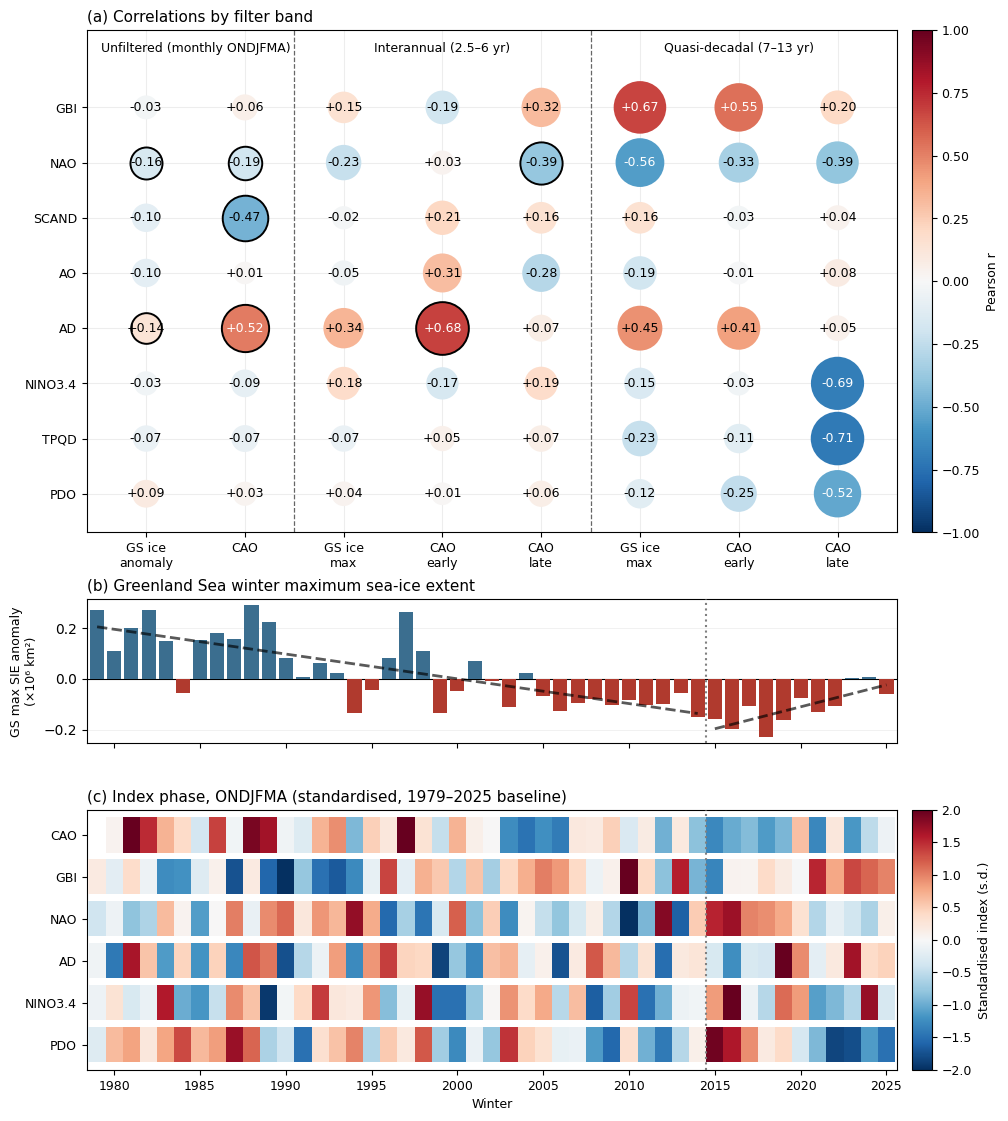

In [30]:
log_processing_step(logger, 'Creating alternative single-column figure')

# ---- panel heights: keep (b) and (c) at their EXACT original sizes ----
ratio_b = 1.0
ratio_c = max(1.4, 0.30 * N_RIBBON)
b_height_alt = RIBBON_HEIGHT * ratio_b / (ratio_b + ratio_c)
c_height_alt = RIBBON_HEIGHT * ratio_c / (ratio_b + ratio_c)

# ---- panel (a) height: same per-row allowance as the primary figure ---
a_height_alt = 0.62 * len(INDEX_LABELS_MATRIX) + 1.3

total_width_alt = RIBBON_WIDTH   # single column, same width as (b)/(c)
total_height_alt = a_height_alt + b_height_alt + c_height_alt

fig2 = plt.figure(figsize=(total_width_alt, total_height_alt))
outer2 = fig2.add_gridspec(3, 1,
                           height_ratios=[a_height_alt, b_height_alt, c_height_alt],
                           hspace=0.22, left=0.11, right=0.92, top=0.97, bottom=0.05)

# ==================================================================
# PANEL (a): band-triplet matrix, variable column count per band --
# unfiltered has 2 columns (GS ice anomaly, CAO), the DJFM bands keep 3
# (GS ice max, CAO early, CAO late). Column positions are cumulative
# rather than a fixed band-width multiple, since the band widths differ.
# ==================================================================
ax_a2 = fig2.add_subplot(outer2[0])
norm_a2 = TwoSlopeNorm(vmin=-VLIM_MATRIX, vcenter=0, vmax=VLIM_MATRIX)
cmap_a2 = plt.get_cmap(CMAP_MATRIX)

# Visual (diameter) scale for this panel's markers only -- matplotlib's
# scatter 's' is AREA, so this needs squaring (1.5**2) to get a true 1.5x
# visual enlargement, not a bare 1.5x (which would only look ~1.22x bigger).
# Scoped to this panel/cell only -- MIN_MARKER_SIZE/MARKER_SCALE themselves
# are untouched, so the primary side-by-side figure's panel (a) is unaffected.
CIRCLE_SCALE_ALT = 1.5

col_labels_alt = []
band_col_range = {}   # band -> (first_col, n_cols)
col_offset = 0
for band in ALT_BANDS:
    tgts = ALT_TARGETS_BY_BAND[band]
    band_col_range[band] = (col_offset, len(tgts))
    col_labels_alt.extend(ALT_TARGET_LABELS_BY_BAND[band])
    col_offset += len(tgts)
n_cols_alt = col_offset

for band in ALT_BANDS:
    r_b, p_b = alt_band_data[band]
    first_col, _ = band_col_range[band]
    for t_idx, tgt in enumerate(ALT_TARGETS_BY_BAND[band]):
        j = first_col + t_idx
        for i, idx in enumerate(INDICES):
            rv, pv = r_b.loc[idx, tgt], p_b.loc[idx, tgt]
            y = len(INDICES) - 1 - i
            ax_a2.scatter(j, y, s=(MIN_MARKER_SIZE + MARKER_SCALE * abs(rv)) * CIRCLE_SCALE_ALT**2,
                         c=[cmap_a2(norm_a2(rv))],
                         edgecolors='k' if pv < P_THRESHOLD else 'none',
                         linewidths=1.4, zorder=3)
            # Significance is shown by the marker's black outline alone
            # (edgecolors, set above) -- no asterisk needed alongside it.
            ax_a2.text(j, y, f'{rv:+.2f}', ha='center', va='center',
                      fontsize=9, zorder=4,
                      color='w' if abs(rv) > 0.5 else 'k')

# grey dashed dividers between band groups (at each band's first column,
# skipping the very first band which has no divider before it)
for band in ALT_BANDS[1:]:
    first_col, _ = band_col_range[band]
    ax_a2.axvline(first_col - 0.5, color='0.4', linewidth=0.9,
                 linestyle='--', zorder=1)

ax_a2.set_xticks(range(n_cols_alt))
ax_a2.set_xticklabels(col_labels_alt, fontsize=9)
ax_a2.set_xlim(-0.6, n_cols_alt - 0.4)
ax_a2.set_ylim(-0.7, len(INDICES) + 0.4)   # headroom reserved for band-group labels
ax_a2.set_yticks(range(len(INDICES)))
ax_a2.set_yticklabels(INDEX_LABELS_MATRIX[::-1], fontsize=9)
ax_a2.grid(alpha=0.22, zorder=0)
ax_a2.set_axisbelow(True)
ax_a2.set_title('(a) Correlations by filter band', fontsize=11, loc='left')

# band-group labels centred above each group (width-aware, not a fixed offset)
for band in ALT_BANDS:
    first_col, n_cols_band = band_col_range[band]
    x_center = first_col + (n_cols_band - 1) / 2
    ax_a2.text(x_center, len(INDICES) - 0.05, ALT_BAND_LABELS[band],
              ha='center', va='bottom', fontsize=9, fontweight='medium')

_pa2 = ax_a2.get_position()
cbar_a2_width_frac = CBAR_WIDTH_IN / total_width_alt
cbar_a2_ax = fig2.add_axes([_pa2.x1 + 0.015, _pa2.y0, cbar_a2_width_frac, _pa2.height])
cb_a2 = fig2.colorbar(plt.cm.ScalarMappable(norm=norm_a2, cmap=cmap_a2), cax=cbar_a2_ax)
cb_a2.set_label('Pearson r', fontsize=9)
cb_a2.ax.tick_params(labelsize=9)

# ==================================================================
# PANELS (b), (c): identical drawing code to the primary figure
# ==================================================================
xlim = (ANALYSIS_START - 0.6, ANALYSIS_END + 0.6)

ax_b2 = fig2.add_subplot(outer2[1])
ice_full = ice.reindex(years)
ice_anom = ice_full - ice_full.dropna().mean()
bar_colors = [COLOR_ICE_POS if v >= 0 else COLOR_ICE_NEG
              for v in ice_anom.fillna(0)]
ax_b2.bar(years, ice_anom.values, color=bar_colors, width=0.82, zorder=3)
ax_b2.axhline(0, color='k', linewidth=0.8, zorder=2)
ax_b2.axvline(SPLIT_YEAR - 0.5, color='gray', linestyle=':', linewidth=1.5, zorder=4)
for mask in (years < SPLIT_YEAR, years >= SPLIT_YEAR):
    yy, vv = years[mask], ice_anom.values[mask]
    ok = np.isfinite(vv)
    if ok.sum() > 2:
        sl_, ic_, *_ = scipy_stats.linregress(yy[ok], vv[ok])
        ax_b2.plot(yy[ok], sl_ * yy[ok] + ic_, '--', color='k',
                  linewidth=2, alpha=0.65, zorder=5)
ax_b2.set_ylabel('GS max SIE anomaly\n(\u00d710\u2076 km\u00b2)', fontsize=9)
ax_b2.set_title('(b) Greenland Sea winter maximum sea-ice extent',
               fontsize=11, loc='left')
ax_b2.grid(True, alpha=0.25, linewidth=0.5, axis='y')
ax_b2.set_axisbelow(True)
ax_b2.set_xlim(*xlim)
ax_b2.tick_params(labelbottom=False)

ax_c2 = fig2.add_subplot(outer2[2], sharex=ax_b2)
norm_c2 = TwoSlopeNorm(vmin=-PHASE_VLIM, vcenter=0, vmax=PHASE_VLIM)
cmap_c2 = plt.get_cmap(CMAP_PHASE)
ytick_pos2, ytick_lab2 = [], []
for i, (lab, sk, sl) in enumerate(RIBBON_ROWS):
    y = N_RIBBON - 1 - i
    series = (z_cao[sk] if lab == 'CAO' else z_index[(lab, sk)]).reindex(years)
    for yr, v in series.items():
        if not np.isfinite(v):
            continue
        ax_c2.add_patch(Rectangle(
            (yr - 0.5, y - 0.42), 1.0, 0.84,
            facecolor=cmap_c2(norm_c2(np.clip(v, -PHASE_VLIM, PHASE_VLIM))),
            edgecolor='none', zorder=3))
    ytick_pos2.append(y)
    ytick_lab2.append(lab)
ax_c2.axvline(SPLIT_YEAR - 0.5, color='gray', linestyle=':', linewidth=1.5, zorder=5)
ax_c2.set_yticks(ytick_pos2)
ax_c2.set_yticklabels(ytick_lab2, fontsize=9)
ax_c2.set_ylim(-0.6, N_RIBBON - 0.4)
ax_c2.set_xlim(*xlim)
ax_c2.xaxis.set_major_locator(ticker.MultipleLocator(5))
ax_c2.tick_params(labelbottom=True, labelsize=9)
ax_c2.set_xlabel('Winter', fontsize=9)
ax_c2.set_title(f'(c) Index phase, ONDJFMA (standardised, '
               f'{ANALYSIS_START}\u2013{ANALYSIS_END} baseline)',
               fontsize=11, loc='left')

_pc2 = ax_c2.get_position()
cbar_c2_width_frac = CBAR_WIDTH_IN / total_width_alt
cbar_c2_ax = fig2.add_axes([_pc2.x1 + 0.015, _pc2.y0, cbar_c2_width_frac, _pc2.height])
cb_c2 = fig2.colorbar(plt.cm.ScalarMappable(norm=norm_c2, cmap=cmap_c2), cax=cbar_c2_ax)
cb_c2.set_label('Standardised index (s.d.)', fontsize=9)
cb_c2.ax.tick_params(labelsize=9)

fname_alt = f'correlation_and_phases_combined_alt_singlecolumn{P_SUFFIX_ALT}.png'
fig2.savefig(OUTPUT_DIR / fname_alt, dpi=DPI, bbox_inches='tight')
log_output_file(logger, 'figure', OUTPUT_DIR / fname_alt)
plt.show()
